In [1]:
from google.colab import files

uploaded = files.upload()

Saving Loan_default.csv to Loan_default.csv


In [2]:
import pandas as pd
import os

filename = list(uploaded.keys())[0]

if filename.endswith('.csv'):
    df = pd.read_csv(filename)
elif filename.endswith(('.xlsx', '.xls')):
    df = pd.read_excel(filename)
else:
    print("Please upload a CSV or Excel file.")

print("Dataset loaded successfully!")
print("Filename:", filename)
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Filename: Loan_default.csv
Dataset shape: (255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [3]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Shape:")
print(df.shape)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  ob

In [4]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

Duplicate Rows:
0


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Available Columns:")
print(df.columns.tolist())

Available Columns:
['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


Loan Default Distribution:
Default
0    225694
1     29653
Name: count, dtype: int64


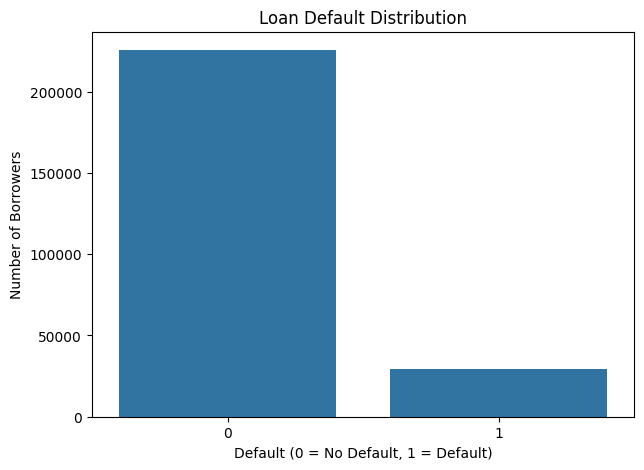

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count loan default cases
print("Loan Default Distribution:")
print(df["Default"].value_counts())

# Plot the distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Default")

plt.title("Loan Default Distribution")
plt.xlabel("Default (0 = No Default, 1 = Default)")
plt.ylabel("Number of Borrowers")

plt.show()

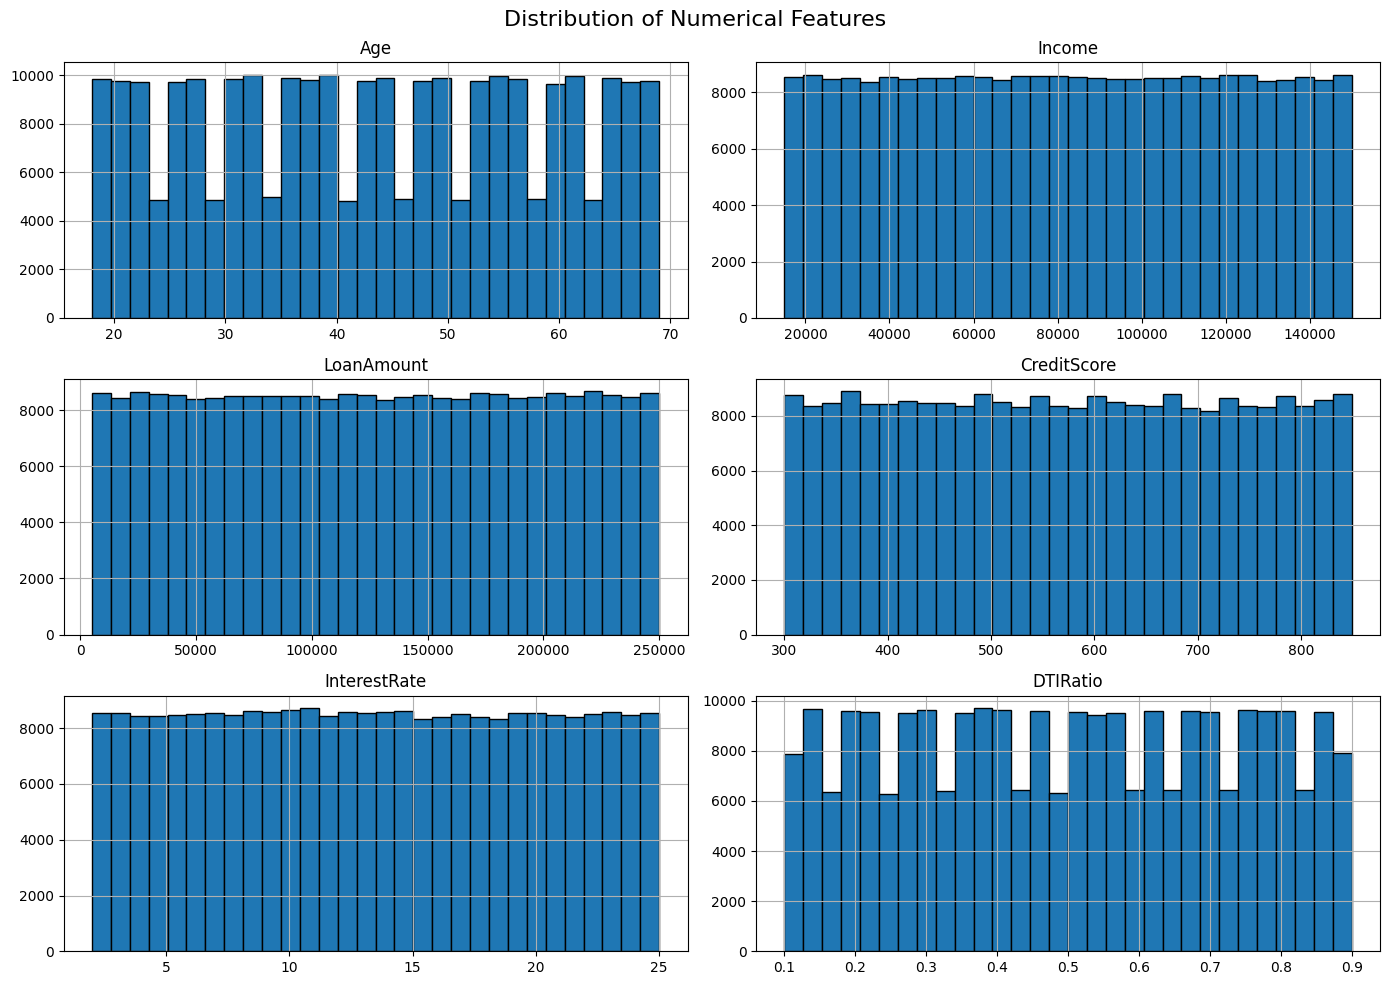

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select important numerical features
features = [
    "Age",
    "Income",
    "LoanAmount",
    "CreditScore",
    "InterestRate",
    "DTIRatio"
]

# Create distribution plots
df[features].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

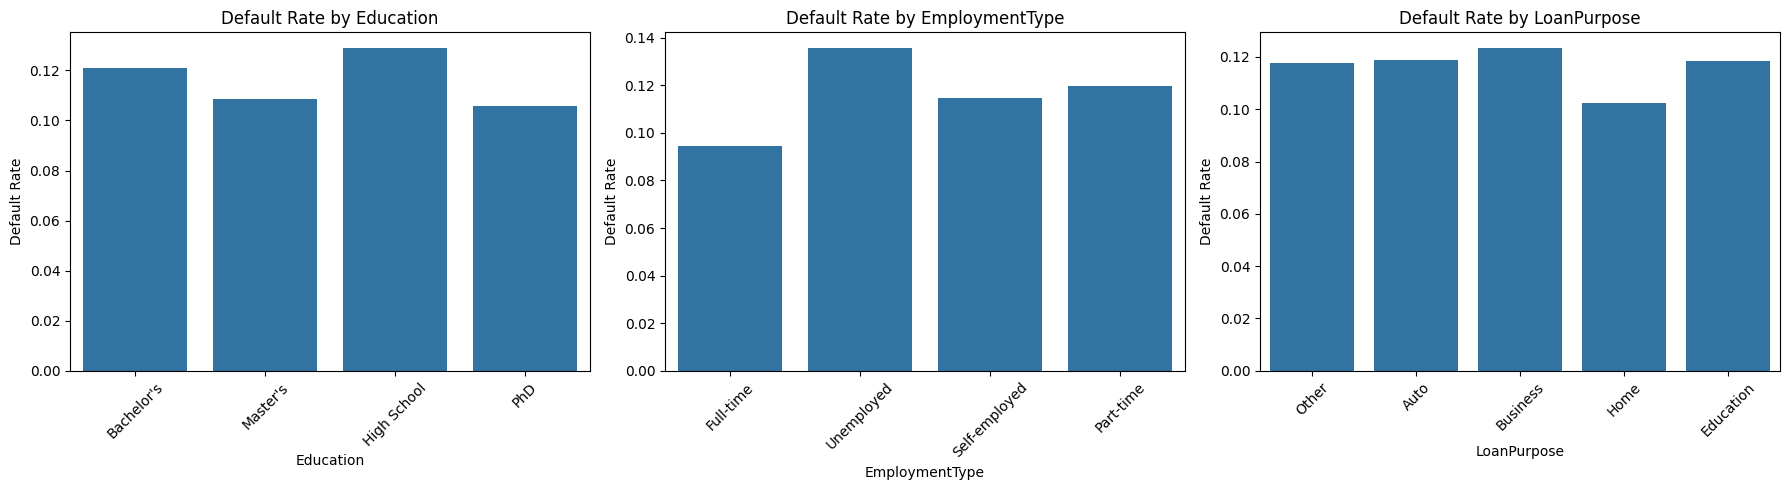

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create charts for categorical features
features = ["Education", "EmploymentType", "LoanPurpose"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(features):
    sns.barplot(
        data=df,
        x=feature,
        y="Default",
        estimator="mean",
        errorbar=None,
        ax=axes[i]
    )

    axes[i].set_title(f"Default Rate by {feature}")
    axes[i].set_ylabel("Default Rate")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [9]:
# Remove LoanID because it is only an identifier
df = df.drop(columns=["LoanID"])

# Separate input features and target
X = df.drop(columns=["Default"])
y = df["Default"]

# Display the results
print("Input Features (X):", X.shape)
print("Target Variable (y):", y.shape)

print("\nInput Feature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Input Features (X): (255347, 16)
Target Variable (y): (255347,)

Input Feature Columns:
['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']

Target Distribution:
Default
0    225694
1     29653
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Default Distribution:")
print(y_train.value_counts())

print("\nTesting Default Distribution:")
print(y_test.value_counts())

Training Features: (204277, 16)
Testing Features: (51070, 16)

Training Target: (204277,)
Testing Target: (51070,)

Training Default Distribution:
Default
0    180555
1     23722
Name: count, dtype: int64

Testing Default Distribution:
Default
0    45139
1     5931
Name: count, dtype: int64


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

# Preprocessing for numerical features
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully!")

Numerical Features:
['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

Categorical Features:
['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']

Preprocessing pipeline created successfully!


In [12]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
print("Training Logistic Regression model...")

logistic_model.fit(X_train, y_train)

print("Model trained successfully!")

Training Logistic Regression model...
Model trained successfully!


LOGISTIC REGRESSION MODEL RESULTS
----------------------------------
Accuracy: 0.8853
Precision: 0.6084
Recall: 0.0341
F1-Score: 0.0645
ROC-AUC: 0.7531

Classification Report:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     45139
           1       0.61      0.03      0.06      5931

    accuracy                           0.89     51070
   macro avg       0.75      0.52      0.50     51070
weighted avg       0.85      0.89      0.84     51070



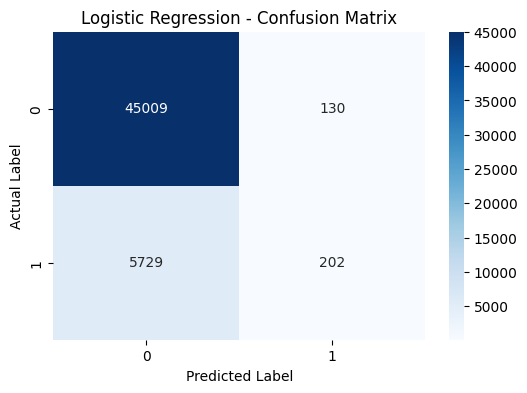

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# Predict on unseen test data
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("LOGISTIC REGRESSION MODEL RESULTS")
print("----------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

Training Decision Tree model...
Decision Tree model trained successfully!

DECISION TREE MODEL RESULTS
---------------------------
Accuracy: 0.6715
Precision: 0.1994
Recall: 0.6068
F1-Score: 0.3002
ROC-AUC: 0.6782

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.68      0.79     45139
           1       0.20      0.61      0.30      5931

    accuracy                           0.67     51070
   macro avg       0.56      0.64      0.54     51070
weighted avg       0.84      0.67      0.73     51070



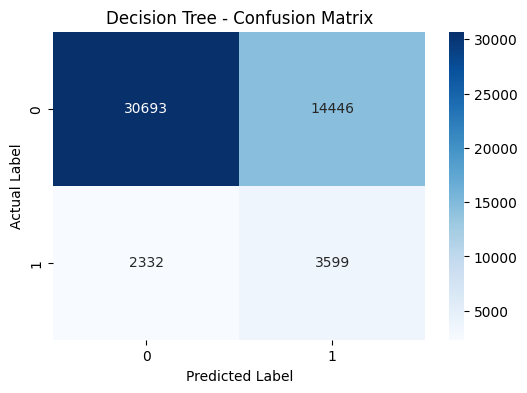

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

# Create the Decision Tree model
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
print("Training Decision Tree model...")

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

# Make predictions
y_pred_dt = decision_tree_model.predict(X_test)
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("\nDECISION TREE MODEL RESULTS")
print("---------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_dt, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_dt, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_dt), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

Training Random Forest model...
Random Forest model trained successfully!

RANDOM FOREST MODEL RESULTS
---------------------------
Accuracy: 0.8363
Precision: 0.3279
Recall: 0.3905
F1-Score: 0.3565
ROC-AUC: 0.7522

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.89      0.91     45139
           1       0.33      0.39      0.36      5931

    accuracy                           0.84     51070
   macro avg       0.62      0.64      0.63     51070
weighted avg       0.85      0.84      0.84     51070



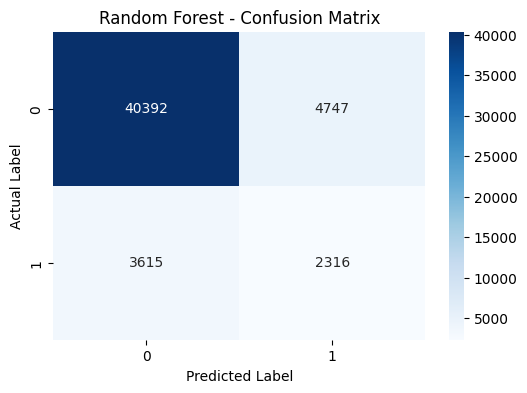

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Create the Random Forest model
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
print("Training Random Forest model...")

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

# Make predictions
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("\nRANDOM FOREST MODEL RESULTS")
print("---------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [16]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Compare all trained models
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8853,0.6084,0.0341,0.0645,0.7531
1,Decision Tree,0.6715,0.1994,0.6068,0.3002,0.6782
2,Random Forest,0.8363,0.3279,0.3905,0.3565,0.7522


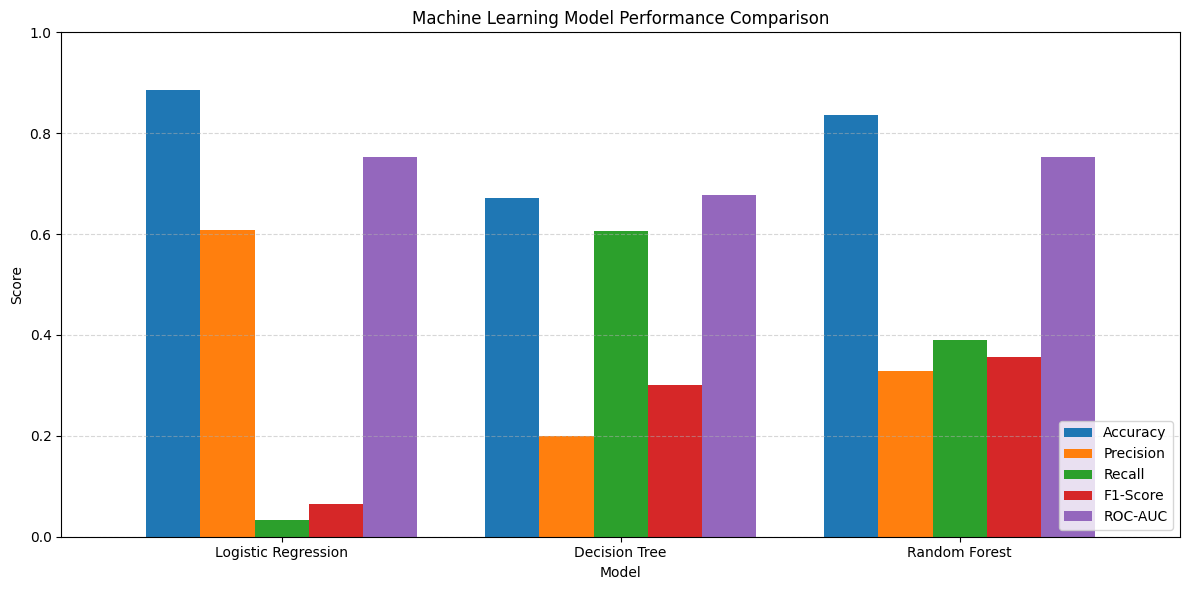

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select evaluation metrics for comparison
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

# Convert results into a format suitable for plotting
plot_df = comparison_df.set_index("Model")[metrics]

# Create comparison chart
plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [18]:
import joblib
import os

# Create a folder to store trained models
os.makedirs("models", exist_ok=True)

# Save all three trained models
joblib.dump(logistic_model, "models/logistic_regression.pkl")
joblib.dump(decision_tree_model, "models/decision_tree.pkl")
joblib.dump(random_forest_model, "models/random_forest.pkl")

print("All models saved successfully!")

print("\nSaved files:")
print(os.listdir("models"))

All models saved successfully!

Saved files:
['decision_tree.pkl', 'logistic_regression.pkl', 'random_forest.pkl']


In [19]:
import shutil

shutil.make_archive(
    "loan_default_models",
    "zip",
    "models"
)

from google.colab import files

files.download("loan_default_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
!pip install -q gradio

In [22]:
import pandas as pd

def predict_loan_default(
    Age,
    Income,
    LoanAmount,
    CreditScore,
    MonthsEmployed,
    NumCreditLines,
    InterestRate,
    LoanTerm,
    DTIRatio,
    Education,
    EmploymentType,
    MaritalStatus,
    HasMortgage,
    HasDependents,
    LoanPurpose,
    HasCoSigner
):
    # Prepare borrower details in the same format as the training data
    borrower = pd.DataFrame([{
        "Age": Age,
        "Income": Income,
        "LoanAmount": LoanAmount,
        "CreditScore": CreditScore,
        "MonthsEmployed": MonthsEmployed,
        "NumCreditLines": NumCreditLines,
        "InterestRate": InterestRate,
        "LoanTerm": LoanTerm,
        "DTIRatio": DTIRatio,
        "Education": Education,
        "EmploymentType": EmploymentType,
        "MaritalStatus": MaritalStatus,
        "HasMortgage": HasMortgage,
        "HasDependents": HasDependents,
        "LoanPurpose": LoanPurpose,
        "HasCoSigner": HasCoSigner
    }])

    # Predict default probability
    probability = random_forest_model.predict_proba(borrower)[0, 1]

    # Predict the class using the model's default threshold
    prediction = random_forest_model.predict(borrower)[0]

    if prediction == 1:
        result = "High Risk: Default Predicted"
    else:
        result = "Lower Risk: Non-Default Predicted"

    return {
        "Prediction": result,
        "Estimated Default Probability": f"{probability * 100:.2f}%"
    }

print("Loan prediction function created successfully!")

Loan prediction function created successfully!


In [23]:
import gradio as gr

with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown(
        """
        # 🏦 Loan Default Risk Prediction
        ### Machine Learning Based Risk Assessment

        Enter the borrower's information below to estimate
        the probability of loan default.
        """
    )

    with gr.Row():
        with gr.Column():
            gr.Markdown("### 👤 Personal Information")

            age = gr.Slider(18, 100, value=30, label="Age")
            income = gr.Number(value=50000, label="Annual Income")
            credit_score = gr.Slider(
                300, 850, value=650, label="Credit Score"
            )

            education = gr.Dropdown(
                choices=sorted(df["Education"].dropna().unique().tolist()),
                label="Education",
                value=df["Education"].mode()[0]
            )

            marital_status = gr.Dropdown(
                choices=sorted(df["MaritalStatus"].dropna().unique().tolist()),
                label="Marital Status",
                value=df["MaritalStatus"].mode()[0]
            )

            dependents = gr.Dropdown(
                choices=sorted(df["HasDependents"].dropna().unique().tolist()),
                label="Has Dependents",
                value=df["HasDependents"].mode()[0]
            )

        with gr.Column():
            gr.Markdown("### 💰 Loan Information")

            loan_amount = gr.Number(value=10000, label="Loan Amount")

            interest_rate = gr.Slider(
                0, 50, value=10, label="Interest Rate (%)"
            )

            loan_term = gr.Number(value=36, label="Loan Term")

            dti_ratio = gr.Slider(
                0, 1, value=0.3, label="Debt-to-Income Ratio"
            )

            num_credit_lines = gr.Slider(
                0, 30, value=3, step=1, label="Number of Credit Lines"
            )

            months_employed = gr.Number(
                value=24, label="Months Employed"
            )

    with gr.Row():
        employment_type = gr.Dropdown(
            choices=sorted(df["EmploymentType"].dropna().unique().tolist()),
            label="Employment Type",
            value=df["EmploymentType"].mode()[0]
        )

        loan_purpose = gr.Dropdown(
            choices=sorted(df["LoanPurpose"].dropna().unique().tolist()),
            label="Loan Purpose",
            value=df["LoanPurpose"].mode()[0]
        )

    with gr.Row():
        mortgage = gr.Dropdown(
            choices=sorted(df["HasMortgage"].dropna().unique().tolist()),
            label="Has Mortgage",
            value=df["HasMortgage"].mode()[0]
        )

        cosigner = gr.Dropdown(
            choices=sorted(df["HasCoSigner"].dropna().unique().tolist()),
            label="Has Co-Signer",
            value=df["HasCoSigner"].mode()[0]
        )

    predict_button = gr.Button(
        "🔍 Predict Loan Default Risk",
        variant="primary"
    )

    prediction_output = gr.JSON(label="Prediction Results")

    predict_button.click(
        fn=predict_loan_default,
        inputs=[
            age,
            income,
            loan_amount,
            credit_score,
            months_employed,
            num_credit_lines,
            interest_rate,
            loan_term,
            dti_ratio,
            education,
            employment_type,
            marital_status,
            mortgage,
            dependents,
            loan_purpose,
            cosigner
        ],
        outputs=prediction_output
    )

    gr.Markdown(
        """
        ---
        **Disclaimer:** This is an academic machine learning project.
        Predictions are estimates and should not be used as the sole
        basis for real financial decisions.
        """
    )

demo.launch(share=True)

/tmp/ipykernel_6082/3719759616.py:3: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://358aabbdf21d6ae2b3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


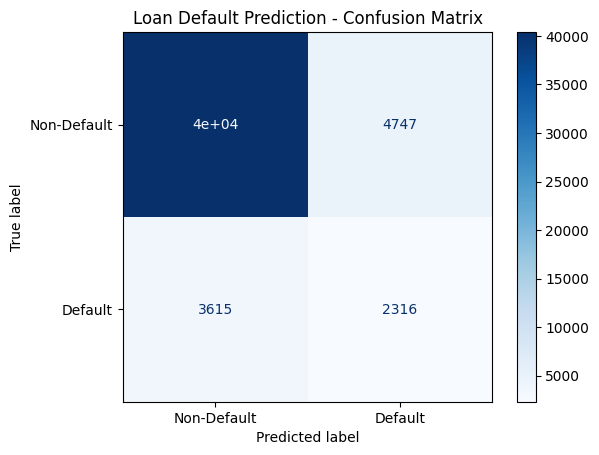

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get predictions from the Random Forest model
y_pred = random_forest_model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Default", "Default"]
)

display.plot(cmap="Blues")
plt.title("Loan Default Prediction - Confusion Matrix")
plt.show()

In [25]:
from sklearn.metrics import classification_report

y_pred = random_forest_model.predict(X_test)

print("Loan Default Prediction - Classification Report")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Default", "Default"]
))

Loan Default Prediction - Classification Report
              precision    recall  f1-score   support

 Non-Default       0.92      0.89      0.91     45139
     Default       0.33      0.39      0.36      5931

    accuracy                           0.84     51070
   macro avg       0.62      0.64      0.63     51070
weighted avg       0.85      0.84      0.84     51070



In [26]:
from sklearn.metrics import classification_report

# Get default probabilities
y_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Try a lower threshold
threshold = 0.30
y_pred_tuned = (y_prob >= threshold).astype(int)

print("Classification Report - Threshold 0.30")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Non-Default", "Default"]
))

Classification Report - Threshold 0.30
              precision    recall  f1-score   support

 Non-Default       0.95      0.57      0.71     45139
     Default       0.19      0.79      0.31      5931

    accuracy                           0.60     51070
   macro avg       0.57      0.68      0.51     51070
weighted avg       0.86      0.60      0.67     51070



In [27]:
from sklearn.metrics import classification_report

# Get default probabilities
y_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Try a lower threshold
threshold = 0.30
y_pred_tuned = (y_prob >= threshold).astype(int)

print("Classification Report - Threshold 0.30")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Non-Default", "Default"]
))

Classification Report - Threshold 0.30
              precision    recall  f1-score   support

 Non-Default       0.95      0.57      0.71     45139
     Default       0.19      0.79      0.31      5931

    accuracy                           0.60     51070
   macro avg       0.57      0.68      0.51     51070
weighted avg       0.86      0.60      0.67     51070



In [32]:
from IPython.display import display as show_table

show_table(threshold_df.round(3))

,Threshold,Precision,Recall,F1-Score
0,0.30,0.194,0.785,0.311
1,0.35,0.222,0.697,0.337
2,0.40,0.253,0.600,0.356
3,0.45,0.288,0.492,0.364
4,0.50,0.328,0.390,0.356
5,0.55,0.370,0.289,0.325
6,0.60,0.421,0.200,0.271


Final Model Evaluation (Threshold = 0.45)
              precision    recall  f1-score   support

 Non-Default       0.93      0.84      0.88     45139
     Default       0.29      0.49      0.36      5931

    accuracy                           0.80     51070
   macro avg       0.61      0.67      0.62     51070
weighted avg       0.85      0.80      0.82     51070



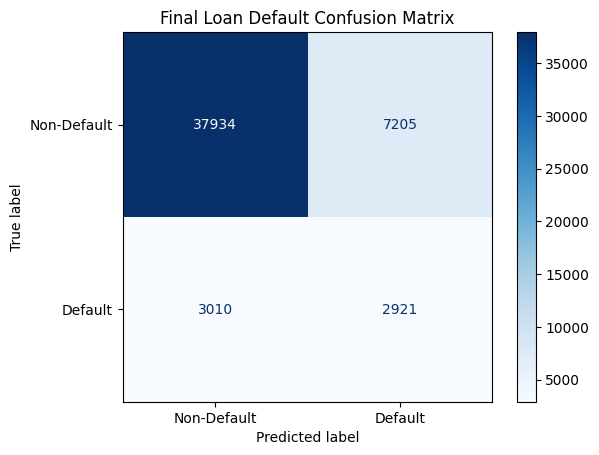

In [33]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Get predicted probabilities
y_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
best_threshold = 0.45
y_pred_final = (y_prob >= best_threshold).astype(int)

# Print classification report
print("Final Model Evaluation (Threshold = 0.45)")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=["Non-Default", "Default"]
))

# Display confusion matrix
cm_final = confusion_matrix(y_test, y_pred_final)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["Non-Default", "Default"]
)

cm_display.plot(cmap="Blues")
plt.title("Final Loan Default Confusion Matrix")
plt.show()

In [34]:
import joblib
import os

# Create folder for the final model
os.makedirs("final_model", exist_ok=True)

# Save the trained Random Forest model
joblib.dump(random_forest_model, "final_model/loan_default_model.pkl")

# Save the selected prediction threshold
joblib.dump(best_threshold, "final_model/decision_threshold.pkl")

print("Final model saved successfully!")
print("Model: loan_default_model.pkl")
print("Threshold:", best_threshold)

Final model saved successfully!
Model: loan_default_model.pkl
Threshold: 0.45


In [35]:
import pandas as pd

def predict_loan_default(
    Age, Income, LoanAmount, CreditScore, MonthsEmployed,
    NumCreditLines, InterestRate, LoanTerm, DTIRatio,
    Education, EmploymentType, MaritalStatus, HasMortgage,
    HasDependents, LoanPurpose, HasCoSigner
):
    borrower = pd.DataFrame([{
        "Age": Age,
        "Income": Income,
        "LoanAmount": LoanAmount,
        "CreditScore": CreditScore,
        "MonthsEmployed": MonthsEmployed,
        "NumCreditLines": NumCreditLines,
        "InterestRate": InterestRate,
        "LoanTerm": LoanTerm,
        "DTIRatio": DTIRatio,
        "Education": Education,
        "EmploymentType": EmploymentType,
        "MaritalStatus": MaritalStatus,
        "HasMortgage": HasMortgage,
        "HasDependents": HasDependents,
        "LoanPurpose": LoanPurpose,
        "HasCoSigner": HasCoSigner
    }])

    probability = random_forest_model.predict_proba(borrower)[0, 1]

    prediction = int(probability >= best_threshold)

    if prediction == 1:
        result = "High Risk: Default Predicted"
    else:
        result = "Lower Risk: Non-Default Predicted"

    return {
        "Prediction": result,
        "Estimated Default Probability": f"{probability * 100:.2f}%",
        "Decision Threshold": f"{best_threshold:.2f}"
    }

print("Updated prediction function successfully!")

Updated prediction function successfully!


In [36]:
demo.close()

demo.launch(share=True)

Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://358aabbdf21d6ae2b3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [37]:
import joblib
import os
import shutil
from google.colab import files

# Create a folder for the final model
os.makedirs("final_model", exist_ok=True)

# Save the latest model and threshold
joblib.dump(
    random_forest_model,
    "final_model/loan_default_model.pkl"
)

joblib.dump(
    best_threshold,
    "final_model/decision_threshold.pkl"
)

# Create a ZIP file
shutil.make_archive(
    "loan_default_final_model",
    "zip",
    "final_model"
)

# Download the ZIP file
files.download("loan_default_final_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>